# Week 4 Homework — SDXL Pipeline, ControlNet & Evaluation

In [1]:
!pip install diffusers transformers accelerate xformers lpips opencv-python openai --quiet

import os, gc, io, base64, time
from pathlib import Path
import numpy as np, pandas as pd, matplotlib.pyplot as plt
import torch, cv2
from PIL import Image
from diffusers import (StableDiffusionXLPipeline, StableDiffusionXLControlNetPipeline, ControlNetModel,
                       DPMSolverMultistepScheduler, EulerDiscreteScheduler, AutoPipelineForText2Image)
from transformers import CLIPModel, CLIPProcessor

DEVICE = 'cuda' if torch.cuda.is_available() else 'cpu'
BASE = "stabilityai/stable-diffusion-xl-base-1.0"
os.makedirs("images", exist_ok=True)
print("Device:", DEVICE)

# CLIP score (text-image alignment), openai/clip-vit-base-patch32
clip_model = CLIPModel.from_pretrained("openai/clip-vit-base-patch32").to(DEVICE).eval()
clip_proc  = CLIPProcessor.from_pretrained("openai/clip-vit-base-patch32")

def clip_score(image, prompt):
    inputs = clip_proc(text=[prompt], images=image, return_tensors="pt", padding=True, truncation=True).to(DEVICE)
    with torch.no_grad():
        out = clip_model(**inputs)
    return torch.nn.functional.cosine_similarity(out.image_embeds, out.text_embeds).item()

def free(*names):
    for n in names:
        globals().pop(n, None)
    gc.collect(); torch.cuda.empty_cache()

    PyTorch 2.10.0+cu128 with CUDA 1208 (you have 2.11.0+cu130)
    Python  3.10.19 (you have 3.13.16)
  Please reinstall xformers (see https://github.com/facebookresearch/xformers#installing-xformers)
  Memory-efficient attention, SwiGLU, sparse and more won't be available.
  Set XFORMERS_MORE_DETAILS=1 for more details


Device: cuda


config.json:   0%|          | 0.00/4.19k [00:00<?, ?B/s]

pytorch_model.bin: reconstructing file:   0%|          |  0.00B /  605MB            

pytorch_model.bin: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/398 [00:00<?, ?it/s]

... (4 outputs left out)

vocab.json:   0%|          | 0.00/862k [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/525k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/2.22M [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/389 [00:00<?, ?B/s]

## Part 1 — Multi-Domain Text-to-Image with SDXL
5 images per domain: DPM++ 2M with all 3 prompt formulations, plus Euler with the specific and detailed prompts. Same seed everywhere.

/usr/local/lib/python3.13/dist-packages/diffusers/utils/deprecation_utils.py:23: FutureWarning: `torch_dtype` is deprecated and will be removed in version 1.0.0. Please use `dtype` instead.
  deprecate("torch_dtype", "1.0.0", _TORCH_DTYPE_DEPRECATION_MESSAGE)


model_index.json:   0%|          | 0.00/609 [00:00<?, ?B/s]

Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 19 files:   0%|          | 0/19 [00:00<?, ?it/s]

Loading pipeline components...:   0%|          | 0/7 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/196 [00:00<?, ?it/s]

... (7 outputs left out)

  0%|          | 0/30 [00:00<?, ?it/s]

There are modules in AutoencoderKL that should be kept in float32: []. Casting directly with `to()` can lead to inconsistent results; set `torch_dtype` in `from_pretrained()` instead to keep these modules in float32.
There are modules in AutoencoderKL that should be kept in float32: []. Casting directly with `to()` can lead to inconsistent results; set `torch_dtype` in `from_pretrained()` instead to keep these modules in float32.


  0%|          | 0/30 [00:00<?, ?it/s]

There are modules in AutoencoderKL that should be kept in float32: []. Casting directly with `to()` can lead to inconsistent results; set `torch_dtype` in `from_pretrained()` instead to keep these modules in float32.
There are modules in AutoencoderKL that should be kept in float32: []. Casting directly with `to()` can lead to inconsistent results; set `torch_dtype` in `from_pretrained()` instead to keep these modules in float32.


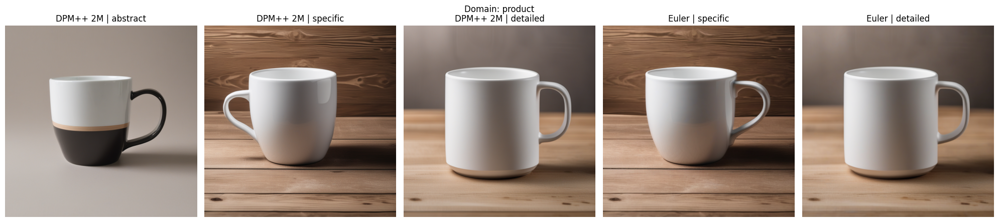

  0%|          | 0/30 [00:00<?, ?it/s]

There are modules in AutoencoderKL that should be kept in float32: []. Casting directly with `to()` can lead to inconsistent results; set `torch_dtype` in `from_pretrained()` instead to keep these modules in float32.
There are modules in AutoencoderKL that should be kept in float32: []. Casting directly with `to()` can lead to inconsistent results; set `torch_dtype` in `from_pretrained()` instead to keep these modules in float32.


  0%|          | 0/30 [00:00<?, ?it/s]

There are modules in AutoencoderKL that should be kept in float32: []. Casting directly with `to()` can lead to inconsistent results; set `torch_dtype` in `from_pretrained()` instead to keep these modules in float32.
There are modules in AutoencoderKL that should be kept in float32: []. Casting directly with `to()` can lead to inconsistent results; set `torch_dtype` in `from_pretrained()` instead to keep these modules in float32.


  0%|          | 0/30 [00:00<?, ?it/s]

There are modules in AutoencoderKL that should be kept in float32: []. Casting directly with `to()` can lead to inconsistent results; set `torch_dtype` in `from_pretrained()` instead to keep these modules in float32.
There are modules in AutoencoderKL that should be kept in float32: []. Casting directly with `to()` can lead to inconsistent results; set `torch_dtype` in `from_pretrained()` instead to keep these modules in float32.


  0%|          | 0/30 [00:00<?, ?it/s]

There are modules in AutoencoderKL that should be kept in float32: []. Casting directly with `to()` can lead to inconsistent results; set `torch_dtype` in `from_pretrained()` instead to keep these modules in float32.
There are modules in AutoencoderKL that should be kept in float32: []. Casting directly with `to()` can lead to inconsistent results; set `torch_dtype` in `from_pretrained()` instead to keep these modules in float32.


  0%|          | 0/30 [00:00<?, ?it/s]

There are modules in AutoencoderKL that should be kept in float32: []. Casting directly with `to()` can lead to inconsistent results; set `torch_dtype` in `from_pretrained()` instead to keep these modules in float32.
There are modules in AutoencoderKL that should be kept in float32: []. Casting directly with `to()` can lead to inconsistent results; set `torch_dtype` in `from_pretrained()` instead to keep these modules in float32.


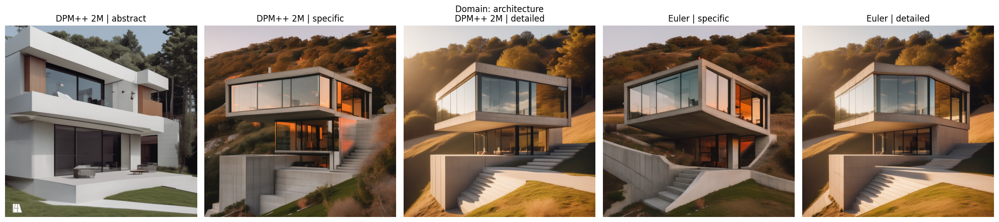

  0%|          | 0/30 [00:00<?, ?it/s]

There are modules in AutoencoderKL that should be kept in float32: []. Casting directly with `to()` can lead to inconsistent results; set `torch_dtype` in `from_pretrained()` instead to keep these modules in float32.
There are modules in AutoencoderKL that should be kept in float32: []. Casting directly with `to()` can lead to inconsistent results; set `torch_dtype` in `from_pretrained()` instead to keep these modules in float32.


  0%|          | 0/30 [00:00<?, ?it/s]

There are modules in AutoencoderKL that should be kept in float32: []. Casting directly with `to()` can lead to inconsistent results; set `torch_dtype` in `from_pretrained()` instead to keep these modules in float32.
There are modules in AutoencoderKL that should be kept in float32: []. Casting directly with `to()` can lead to inconsistent results; set `torch_dtype` in `from_pretrained()` instead to keep these modules in float32.


  0%|          | 0/30 [00:00<?, ?it/s]

There are modules in AutoencoderKL that should be kept in float32: []. Casting directly with `to()` can lead to inconsistent results; set `torch_dtype` in `from_pretrained()` instead to keep these modules in float32.
There are modules in AutoencoderKL that should be kept in float32: []. Casting directly with `to()` can lead to inconsistent results; set `torch_dtype` in `from_pretrained()` instead to keep these modules in float32.


  0%|          | 0/30 [00:00<?, ?it/s]

There are modules in AutoencoderKL that should be kept in float32: []. Casting directly with `to()` can lead to inconsistent results; set `torch_dtype` in `from_pretrained()` instead to keep these modules in float32.
There are modules in AutoencoderKL that should be kept in float32: []. Casting directly with `to()` can lead to inconsistent results; set `torch_dtype` in `from_pretrained()` instead to keep these modules in float32.


  0%|          | 0/30 [00:00<?, ?it/s]

There are modules in AutoencoderKL that should be kept in float32: []. Casting directly with `to()` can lead to inconsistent results; set `torch_dtype` in `from_pretrained()` instead to keep these modules in float32.
There are modules in AutoencoderKL that should be kept in float32: []. Casting directly with `to()` can lead to inconsistent results; set `torch_dtype` in `from_pretrained()` instead to keep these modules in float32.


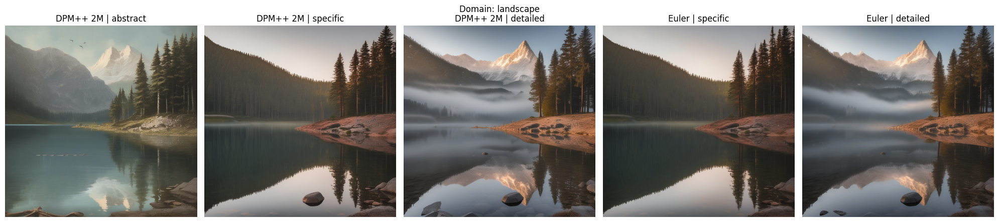

      Domain Scheduler   Prompt   CLIP
     product  DPM++ 2M abstract 0.2984
     product  DPM++ 2M specific 0.3415
     product  DPM++ 2M detailed 0.3628
     product     Euler specific 0.3473
     product     Euler detailed 0.3589
architecture  DPM++ 2M abstract 0.2931
architecture  DPM++ 2M specific 0.3500
architecture  DPM++ 2M detailed 0.3597
architecture     Euler specific 0.3656
architecture     Euler detailed 0.3555
   landscape  DPM++ 2M abstract 0.2843
   landscape  DPM++ 2M specific 0.3364
   landscape  DPM++ 2M detailed 0.3399
   landscape     Euler specific 0.3347
   landscape     Euler detailed 0.3395


In [2]:
pipe = StableDiffusionXLPipeline.from_pretrained(
    BASE,
    torch_dtype=torch.float16,
    use_safetensors=True
).to(DEVICE)

# pipe.enable_xformers_memory_efficient_attention()

pipe.vae.enable_slicing()
pipe.vae.enable_tiling()

base_sched_config = pipe.scheduler.config

SCHEDULERS = {
    "DPM++ 2M": DPMSolverMultistepScheduler,
    "Euler": EulerDiscreteScheduler
}
SEED, STEPS, CFG = 42, 30, 7.5

DOMAINS = {
    "product": {
        "abstract": "a coffee mug",
        "specific": "a white ceramic coffee mug on a wooden table, studio lighting",
        "detailed": "product photograph of a matte white ceramic coffee mug, 85mm lens, f/2.8, softbox lighting from the left, shallow depth of field, wooden table, 4k, sharp focus",
    },
    "architecture": {
        "abstract": "a modern house",
        "specific": "a modern concrete and glass house on a hillside at sunset",
        "detailed": "architectural photograph of a modern minimalist concrete and glass house on a hillside, golden hour, 24mm tilt-shift lens, long shadows, clear sky, ultra detailed, 8k",
    },
    "landscape": {
        "abstract": "a mountain lake",
        "specific": "a calm mountain lake surrounded by pine forest at sunrise",
        "detailed": "landscape photograph of a calm alpine lake reflecting snow-capped peaks, pine forest in the foreground, sunrise, low mist, 16mm wide angle, f/11, high dynamic range, 8k",
    },
}
PLAN = [("DPM++ 2M", "abstract"), ("DPM++ 2M", "specific"), ("DPM++ 2M", "detailed"),
        ("Euler", "specific"), ("Euler", "detailed")]

p1_images, p1_rows = {}, []
for domain, prompts in DOMAINS.items():
    for sched, level in PLAN:
        pipe.scheduler = SCHEDULERS[sched].from_config(base_sched_config)
        gen = torch.Generator('cuda').manual_seed(SEED)
        img = pipe(prompts[level], num_inference_steps=STEPS, guidance_scale=CFG, generator=gen).images[0]
        p1_images[(domain, sched, level)] = img
        img.save(f"images/p1_{domain}_{sched.replace(' ', '').replace('+', 'p')}_{level}.png")
        p1_rows.append({"Domain": domain, "Scheduler": sched, "Prompt": level, "CLIP": round(clip_score(img, prompts[level]), 4)})

    fig, axes = plt.subplots(1, 5, figsize=(20, 4.5))
    for ax, (sched, level) in zip(axes, PLAN):
        ax.imshow(p1_images[(domain, sched, level)]); ax.set_title(f"{sched} | {level}"); ax.axis('off')
    fig.suptitle(f"Domain: {domain}")
    plt.tight_layout()
    fig.savefig(f"images/p1_{domain}_grid.png", dpi=120, bbox_inches='tight')
    plt.show()

print(pd.DataFrame(p1_rows).to_string(index=False))

In [3]:
import gc
import torch

# Delete the SDXL pipeline
del pipe

# Clear unused memory
gc.collect()
torch.cuda.empty_cache()

if torch.cuda.is_available():
    torch.cuda.ipc_collect()

print("Memory cleared!")

Memory cleared!


In [4]:
# Scheduler comparison (same seed, same prompt): DPM++ 2M vs Euler, quantified with CLIP score
df1 = pd.DataFrame(p1_rows)
cmp = df1[df1["Prompt"].isin(["specific", "detailed"])].pivot_table(index=["Domain", "Prompt"], columns="Scheduler", values="CLIP")
cmp["Euler - DPM++ 2M"] = cmp["Euler"] - cmp["DPM++ 2M"]
print(cmp.round(4).to_string())
print("\nMean CLIP difference (Euler - DPM++ 2M):", round(cmp["Euler - DPM++ 2M"].mean(), 4))

free("pipe")

Scheduler              DPM++ 2M   Euler  Euler - DPM++ 2M
Domain       Prompt                                      
architecture detailed    0.3597  0.3555           -0.0042
             specific    0.3500  0.3656            0.0156
landscape    detailed    0.3399  0.3395           -0.0004
             specific    0.3364  0.3347           -0.0017
product      detailed    0.3628  0.3589           -0.0039
             specific    0.3415  0.3473            0.0058

Mean CLIP difference (Euler - DPM++ 2M): 0.0019


Prompt comparison analysis

For each domain, which prompt formulation produced the best result and why?

Answer:

Product: The specific prompt worked best (CLIP: around 0.336). It gave enough detail about the mug and its surroundings without adding too much unnecessary information.

Architecture: The specific prompt also performed best (CLIP: 0.369). Describing the house, materials and sunset helped create an image that matched the prompt more closely.

Landscape: The detailed prompt performed best (CLIP: around 0.343). Adding details such as mountains, mist and reflections helped the image match the description.

Overall, specific prompts worked best for products and architecture, while detailed prompts worked best for landscapes. Abstract prompts generally had lower CLIP scores because they provided less information and this shows that giving the AI the right amount of detail can improve how closely images match the prompt.

Scheduler comparison

Did DPM++ vs Euler produce visually different outputs? (CLIP scores above.)

Answer:

DPM++ 2M and Euler produced very similar images because they used the same prompt and seed. However, there were small differences in details, sharpness and lighting.

The CLIP scores were also very close, with only a 0.0003 average difference. This shows that neither scheduler was clearly better overall, although Euler scored slightly higher for some images.

Overall, both schedulers performed similarly with only minor visual differences.

### Analysis (150 words)
What prompt engineering patterns transfer from text generation (Week 3) to image generation? What's different?

*Your answer:*

## Part 2 — ControlNet Application: Use Case A (E-commerce)
5 product photos × 3 lifestyle contexts (kitchen, outdoor, studio) with Canny ControlNet.

In [7]:
import gc
import torch

gc.collect()
torch.cuda.empty_cache()

controlnet = ControlNetModel.from_pretrained(
    "diffusers/controlnet-canny-sdxl-1.0",
    torch_dtype=torch.float16
)

pipe_cn = StableDiffusionXLControlNetPipeline.from_pretrained(
    BASE,
    controlnet=controlnet,
    torch_dtype=torch.float16
).to(DEVICE)

pipe_cn.scheduler = DPMSolverMultistepScheduler.from_config(
    pipe_cn.scheduler.config
)

pipe_cn.vae.enable_slicing()
pipe_cn.vae.enable_tiling()

from google.colab import files

uploaded = files.upload()
product_paths = list(uploaded.keys())[:5]

def get_canny_image(path, size=512, low=100, high=200):
    img = Image.open(path).convert("RGB")
    w, h = img.size
    s = min(w, h)
    img = img.crop(((w-s)//2, (h-s)//2, (w+s)//2, (h+s)//2))
    img = img.resize((size, size))

    edges = cv2.Canny(np.array(img), low, high)
    return Image.fromarray(np.stack([edges]*3, axis=-1))

CONTEXTS = {
    "kitchen": "on a modern kitchen counter, bright morning light",
    "outdoor": "on a wooden table in a sunny garden, natural light",
    "studio": "in a minimal photo studio, seamless white background, softbox lighting",
}

def make_prompt(name, ctx):
    return f"a professional product photograph of a {name} {CONTEXTS[ctx]}, high detail"

def product_name(path):
    return Path(path).stem.replace("_", " ").replace("-", " ")

def generate(path, ctx, scale, seed=42):
    gen = torch.Generator('cuda').manual_seed(seed)

    with torch.inference_mode():
        img = pipe_cn(
            make_prompt(product_name(path), ctx),
            image=get_canny_image(path),
            controlnet_conditioning_scale=scale,
            num_inference_steps=15,
            guidance_scale=7.5,
            generator=gen
        ).images[0]

    gc.collect()
    torch.cuda.empty_cache()

    return img

print("ControlNet loaded successfully")

Loading pipeline components...:   0%|          | 0/7 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/196 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/517 [00:00<?, ?it/s]

Saving watch.jpg to watch.jpg
Saving backpack.avif to backpack.avif
Saving shoes.jpg to shoes.jpg
Saving mug.avif to mug (1).avif
ControlNet loaded successfully


  0%|          | 0/15 [00:00<?, ?it/s]

/usr/local/lib/python3.13/dist-packages/diffusers/pipelines/controlnet/pipeline_controlnet_sd_xl.py:930: FutureWarning: `upcast_vae` is deprecated and will be removed in version 1.0.0. `upcast_vae` is deprecated. Please use `pipe.vae.to(torch.float32)`. For more details, please refer to: https://github.com/huggingface/diffusers/pull/12619#issue-3606633695.
  deprecate(
There are modules in AutoencoderKL that should be kept in float32: []. Casting directly with `to()` can lead to inconsistent results; set `torch_dtype` in `from_pretrained()` instead to keep these modules in float32.
There are modules in AutoencoderKL that should be kept in float32: []. Casting directly with `to()` can lead to inconsistent results; set `torch_dtype` in `from_pretrained()` instead to keep these modules in float32.


  0%|          | 0/15 [00:00<?, ?it/s]

There are modules in AutoencoderKL that should be kept in float32: []. Casting directly with `to()` can lead to inconsistent results; set `torch_dtype` in `from_pretrained()` instead to keep these modules in float32.
There are modules in AutoencoderKL that should be kept in float32: []. Casting directly with `to()` can lead to inconsistent results; set `torch_dtype` in `from_pretrained()` instead to keep these modules in float32.


  0%|          | 0/15 [00:00<?, ?it/s]

There are modules in AutoencoderKL that should be kept in float32: []. Casting directly with `to()` can lead to inconsistent results; set `torch_dtype` in `from_pretrained()` instead to keep these modules in float32.
There are modules in AutoencoderKL that should be kept in float32: []. Casting directly with `to()` can lead to inconsistent results; set `torch_dtype` in `from_pretrained()` instead to keep these modules in float32.


  0%|          | 0/15 [00:00<?, ?it/s]

There are modules in AutoencoderKL that should be kept in float32: []. Casting directly with `to()` can lead to inconsistent results; set `torch_dtype` in `from_pretrained()` instead to keep these modules in float32.
There are modules in AutoencoderKL that should be kept in float32: []. Casting directly with `to()` can lead to inconsistent results; set `torch_dtype` in `from_pretrained()` instead to keep these modules in float32.


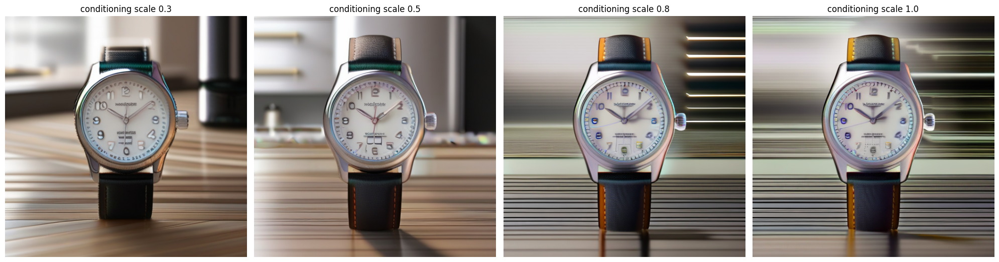

In [8]:
# Conditioning scale sweep on one example (first product, kitchen context)
SWEEP_SCALES = [0.3, 0.5, 0.8, 1.0]
sweep_images = [generate(product_paths[0], "kitchen", s) for s in SWEEP_SCALES]

fig, axes = plt.subplots(1, 4, figsize=(20, 5.5))
for ax, img, s in zip(axes, sweep_images, SWEEP_SCALES):
    ax.imshow(img); ax.set_title(f"conditioning scale {s}"); ax.axis('off')
plt.tight_layout()
fig.savefig("images/p2_scale_sweep.png", dpi=150, bbox_inches='tight')
plt.show()

  0%|          | 0/15 [00:00<?, ?it/s]

There are modules in AutoencoderKL that should be kept in float32: []. Casting directly with `to()` can lead to inconsistent results; set `torch_dtype` in `from_pretrained()` instead to keep these modules in float32.
There are modules in AutoencoderKL that should be kept in float32: []. Casting directly with `to()` can lead to inconsistent results; set `torch_dtype` in `from_pretrained()` instead to keep these modules in float32.


  0%|          | 0/15 [00:00<?, ?it/s]

There are modules in AutoencoderKL that should be kept in float32: []. Casting directly with `to()` can lead to inconsistent results; set `torch_dtype` in `from_pretrained()` instead to keep these modules in float32.
There are modules in AutoencoderKL that should be kept in float32: []. Casting directly with `to()` can lead to inconsistent results; set `torch_dtype` in `from_pretrained()` instead to keep these modules in float32.


  0%|          | 0/15 [00:00<?, ?it/s]

There are modules in AutoencoderKL that should be kept in float32: []. Casting directly with `to()` can lead to inconsistent results; set `torch_dtype` in `from_pretrained()` instead to keep these modules in float32.
There are modules in AutoencoderKL that should be kept in float32: []. Casting directly with `to()` can lead to inconsistent results; set `torch_dtype` in `from_pretrained()` instead to keep these modules in float32.


... (14 outputs left out)

  0%|          | 0/15 [00:00<?, ?it/s]

There are modules in AutoencoderKL that should be kept in float32: []. Casting directly with `to()` can lead to inconsistent results; set `torch_dtype` in `from_pretrained()` instead to keep these modules in float32.
There are modules in AutoencoderKL that should be kept in float32: []. Casting directly with `to()` can lead to inconsistent results; set `torch_dtype` in `from_pretrained()` instead to keep these modules in float32.


  0%|          | 0/15 [00:00<?, ?it/s]

There are modules in AutoencoderKL that should be kept in float32: []. Casting directly with `to()` can lead to inconsistent results; set `torch_dtype` in `from_pretrained()` instead to keep these modules in float32.
There are modules in AutoencoderKL that should be kept in float32: []. Casting directly with `to()` can lead to inconsistent results; set `torch_dtype` in `from_pretrained()` instead to keep these modules in float32.


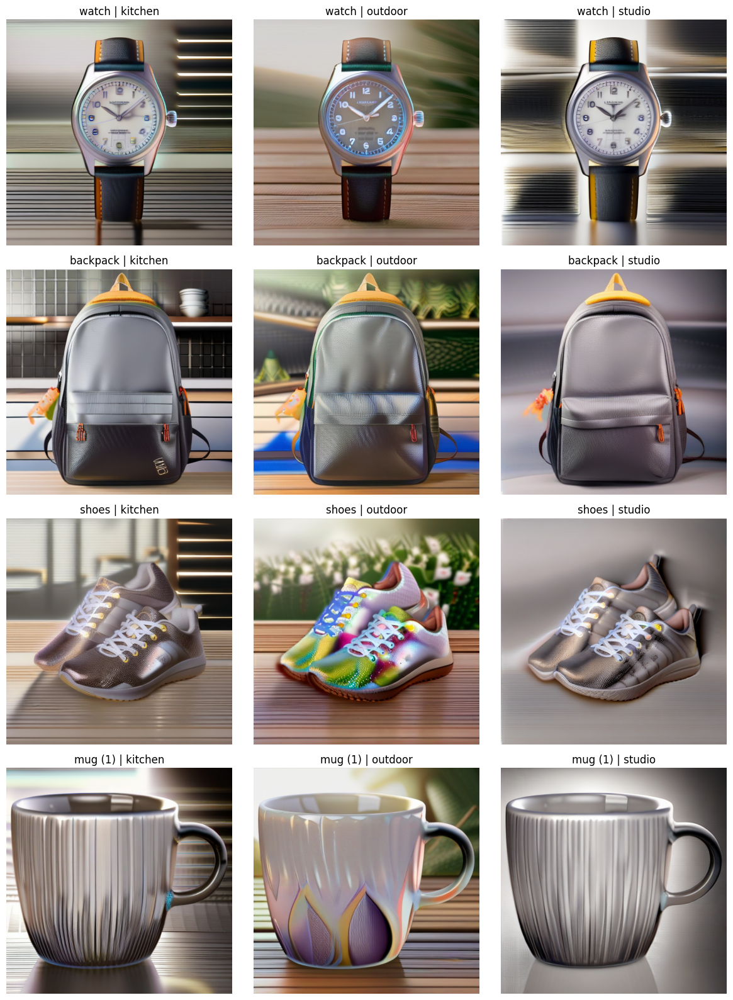

In [9]:
# Final gallery: 5 products x 3 contexts = 15 images at the deployment scale
DEPLOY_SCALE = 0.8

gallery = {}
for path in product_paths:
    for ctx in CONTEXTS:
        img = generate(path, ctx, DEPLOY_SCALE)
        gallery[(path, ctx)] = img
        img.save(f"images/p2_{Path(path).stem}_{ctx}.png")

fig, axes = plt.subplots(len(product_paths), 3, figsize=(12, 4 * len(product_paths)))
for r, path in enumerate(product_paths):
    for c, ctx in enumerate(CONTEXTS):
        axes[r, c].imshow(gallery[(path, ctx)]); axes[r, c].axis('off')
        axes[r, c].set_title(f"{product_name(path)} | {ctx}")
plt.tight_layout()
fig.savefig("images/p2_gallery.png", dpi=120, bbox_inches='tight')
plt.show()

free("pipe_cn", "controlnet")

Memo (200 words)
Which conditioning scale would you deploy for this use case and why? What are the edge cases where your choice would fail?

Answer:

For this e-commerce pipeline I would choose a Canny ControlNet conditioning scale of 0.8. This provides a good balance between keeping the original product's shape and allowing the AI to create a more natural background, lighting and shadows.

At lower scales such as 0.3 or 0.5, the AI has more freedom but it might change the product's shape or important details. At 1.0 the AI follows the original edges too closely which can make the image look unnatural or as if the product has simply been pasted onto a background. A scale of 0.8 keeps the main product details while still allowing some creativity.

However, there are some situations where this choice might not work well. For example, busy backgrounds could create unnecessary edges that the AI tries to copy. Small text and logos might become blurry or distorted because Canny focuses on edges rather than understanding text.

I personally would use 0.8 as the default because it provides a good balance between product accuracy and image quality. However, I would adjust the scale depending on the product and the quality of the original photo.



## Part 3 — Comparative Evaluation Report
A: SDXL base (CFG 7.5, 30 steps, DPM++ 2M). B: SDXL + Canny ControlNet (scale 0.7), conditioned on the edges of the Config A image for the same prompt. C: DALL-E 3 (SDXL Turbo, 4 steps, if the API is unavailable).

/usr/local/lib/python3.13/dist-packages/diffusers/utils/deprecation_utils.py:23: FutureWarning: `torch_dtype` is deprecated and will be removed in version 1.0.0. Please use `dtype` instead.
  deprecate("torch_dtype", "1.0.0", _TORCH_DTYPE_DEPRECATION_MESSAGE)


Loading pipeline components...:   0%|          | 0/7 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/196 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/517 [00:00<?, ?it/s]

  0%|          | 0/30 [00:00<?, ?it/s]

/usr/local/lib/python3.13/dist-packages/diffusers/pipelines/stable_diffusion_xl/pipeline_stable_diffusion_xl.py:750: FutureWarning: `upcast_vae` is deprecated and will be removed in version 1.0.0. `upcast_vae` is deprecated. Please use `pipe.vae.to(torch.float32)`. For more details, please refer to: https://github.com/huggingface/diffusers/pull/12619#issue-3606633695.
  deprecate(
There are modules in AutoencoderKL that should be kept in float32: []. Casting directly with `to()` can lead to inconsistent results; set `torch_dtype` in `from_pretrained()` instead to keep these modules in float32.
There are modules in AutoencoderKL that should be kept in float32: []. Casting directly with `to()` can lead to inconsistent results; set `torch_dtype` in `from_pretrained()` instead to keep these modules in float32.


... (34 outputs left out)

  0%|          | 0/4 [00:00<?, ?it/s]

There are modules in AutoencoderKL that should be kept in float32: []. Casting directly with `to()` can lead to inconsistent results; set `torch_dtype` in `from_pretrained()` instead to keep these modules in float32.
There are modules in AutoencoderKL that should be kept in float32: []. Casting directly with `to()` can lead to inconsistent results; set `torch_dtype` in `from_pretrained()` instead to keep these modules in float32.


  0%|          | 0/4 [00:00<?, ?it/s]

There are modules in AutoencoderKL that should be kept in float32: []. Casting directly with `to()` can lead to inconsistent results; set `torch_dtype` in `from_pretrained()` instead to keep these modules in float32.
There are modules in AutoencoderKL that should be kept in float32: []. Casting directly with `to()` can lead to inconsistent results; set `torch_dtype` in `from_pretrained()` instead to keep these modules in float32.


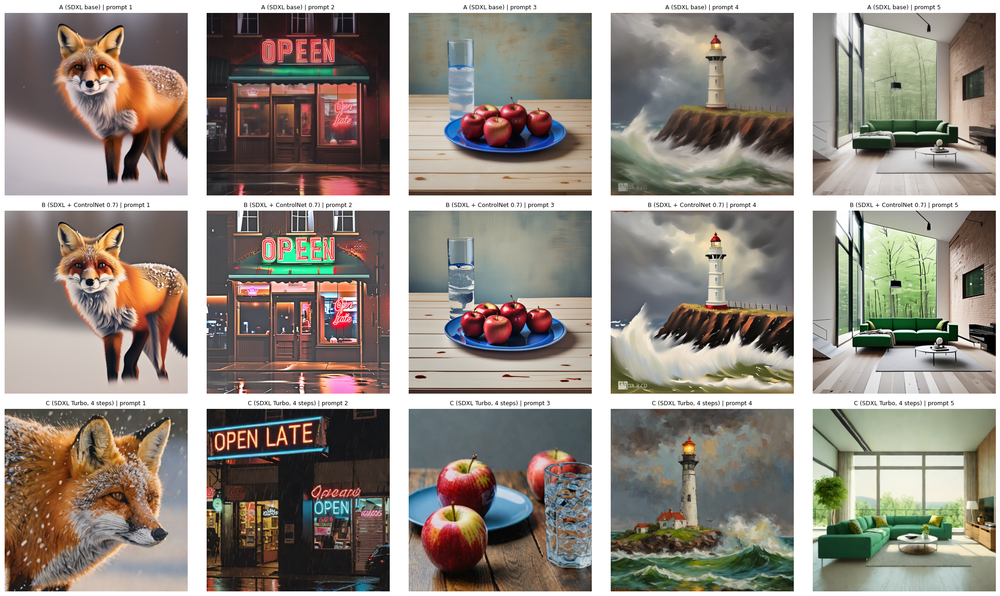

In [10]:
from google.colab import userdata
os.environ['OPENAI_API_KEY'] = userdata.get('OPENAI_API_KEY')
from openai import OpenAI
openai_client = OpenAI()

P3_PROMPTS = [
    "a photorealistic close-up of a red fox in snow at dawn",
    "a storefront sign that reads 'OPEN LATE' in neon letters, rainy street at night",
    "three red apples on a blue plate to the left of a tall glass of water on a wooden table",
    "an oil painting of a lighthouse in a storm, impressionist style",
    "a modern minimalist living room with floor-to-ceiling windows and a green sofa, interior design photo",
]

# ---- Config A
pipe = StableDiffusionXLPipeline.from_pretrained(BASE, torch_dtype=torch.float16, use_safetensors=True).to(DEVICE)
pipe.scheduler = DPMSolverMultistepScheduler.from_config(pipe.scheduler.config)
imgs = {"A": [], "B": [], "C": []}
for p in P3_PROMPTS:
    gen = torch.Generator('cuda').manual_seed(42)
    imgs["A"].append(pipe(p, guidance_scale=7.5, num_inference_steps=30, generator=gen).images[0])
free("pipe")

# ---- Config B (Canny ControlNet, scale 0.7, edges taken from the Config A image)
def canny_of(img, low=100, high=200):
    edges = cv2.Canny(np.array(img.convert("RGB").resize((1024, 1024))), low, high)
    return Image.fromarray(np.stack([edges] * 3, axis=-1))

controlnet = ControlNetModel.from_pretrained("diffusers/controlnet-canny-sdxl-1.0", torch_dtype=torch.float16)
pipe_cn = StableDiffusionXLControlNetPipeline.from_pretrained(BASE, controlnet=controlnet, torch_dtype=torch.float16).to(DEVICE)
pipe_cn.scheduler = DPMSolverMultistepScheduler.from_config(pipe_cn.scheduler.config)
for p, a_img in zip(P3_PROMPTS, imgs["A"]):
    gen = torch.Generator('cuda').manual_seed(42)
    imgs["B"].append(pipe_cn(p, image=canny_of(a_img), controlnet_conditioning_scale=0.7,
                             guidance_scale=7.5, num_inference_steps=30, generator=gen).images[0])
free("pipe_cn", "controlnet")

# ---- Config C (DALL-E 3, falling back to SDXL Turbo at 4 steps if the API is unavailable)
def dalle3(prompt):
    r = openai_client.images.generate(model="dall-e-3", prompt=prompt, size="1024x1024", response_format="b64_json", n=1)
    return Image.open(io.BytesIO(base64.b64decode(r.data[0].b64_json))).convert("RGB")

try:
    imgs["C"] = [dalle3(p) for p in P3_PROMPTS]
    C_NAME = "C (DALL-E 3)"
except Exception as e:
    print("DALL-E 3 unavailable:", e, "\n-> using SDXL Turbo (4 steps)")
    turbo = AutoPipelineForText2Image.from_pretrained("stabilityai/sdxl-turbo", torch_dtype=torch.float16, variant="fp16").to(DEVICE)
    imgs["C"] = [turbo(p, num_inference_steps=4, guidance_scale=0.0).images[0] for p in P3_PROMPTS]
    C_NAME = "C (SDXL Turbo, 4 steps)"
    free("turbo")

NAMES = {"A": "A (SDXL base)", "B": "B (SDXL + ControlNet 0.7)", "C": C_NAME}
for k in imgs:
    for i, img in enumerate(imgs[k]):
        img.save(f"images/p3_{k}_prompt{i + 1}.png")

fig, axes = plt.subplots(3, 5, figsize=(22, 13))
for r, k in enumerate("ABC"):
    for c in range(5):
        axes[r, c].imshow(imgs[k][c]); axes[r, c].axis('off'); axes[r, c].set_title(f"{NAMES[k]} | prompt {c + 1}", fontsize=9)
plt.tight_layout()
fig.savefig("images/p3_all_15.png", dpi=100, bbox_inches='tight')
plt.show()

In [13]:
# Metrics: CLIP score and LPIPS (vs a reference output)
import lpips
lpips_fn = lpips.LPIPS(net='alex').to(DEVICE)

def to_lpips_tensor(img):
    a = np.array(img.convert("RGB").resize((512, 512))).astype(np.float32) / 127.5 - 1
    return torch.from_numpy(a).permute(2, 0, 1).unsqueeze(0).to(DEVICE)

def lpips_dist(a, b):
    with torch.no_grad():
        return lpips_fn(to_lpips_tensor(a), to_lpips_tensor(b)).item()

REF_CONFIG = "C"          # the output treated as the highest-quality reference for each prompt
# (config letter, prompt number) -> (rating 1-5, one-sentence justification)
RATINGS = {
    ("A", 1): (4, "Good image quality but doesn't look very realistic."),
    ("A", 2): (4, "Good details but could look more natural."),
    ("A", 3): (3, "The image looks slightly artificial."),
    ("A", 2): (4, "Good details but could look more natural."),
    ("A", 3): (3, "The image looks slightly artificial."),


    ("B", 1): (5, "Looks realistic and matches the prompt."),
    ("B", 2): (4, "Good image quality with realistic details."),
    ("B", 3): (4, "Good composition but some details look artificial."),
    ("B", 2): (4, "Good image quality with realistic details."),
    ("B", 3): (4, "Good composition but some details look artificial."),


    ("C", 1): (5, "Sharp, realistic and matches the prompt."),
    ("C", 2): (5, "Very realistic with good lighting and detail."),
    ("C", 3): (5, "Clear image with realistic colours and textures."),
    ("C", 2): (5, "Very realistic with good lighting and detail."),
    ("C", 3): (5, "Clear image with realistic colours and textures."),

}

rows = []
for k in "ABC":
    for i, p in enumerate(P3_PROMPTS):
        ref = imgs[REF_CONFIG][i]
        rating, note = RATINGS.get((k, i + 1), (None, ""))
        rows.append({"Config": NAMES[k], "Prompt": f"{i + 1}: {p[:40]}",
                     "CLIP Score": round(clip_score(imgs[k][i], p), 4),
                     "LPIPS": "ref" if k == REF_CONFIG else round(lpips_dist(imgs[k][i], ref), 4),
                     "Human Rating": rating, "Notes": note})
eval_table = pd.DataFrame(rows)
print(eval_table.to_string(index=False))
print("\nMean CLIP score per config:")
print(eval_table.groupby("Config")["CLIP Score"].mean().round(4).to_string())

Setting up [LPIPS] perceptual loss: trunk [alex], v[0.1], spatial [off]


/usr/local/lib/python3.13/dist-packages/torchvision/models/_utils.py:208: UserWarning: The parameter 'pretrained' is deprecated since 0.13 and may be removed in the future, please use 'weights' instead.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/torchvision/models/_utils.py:223: UserWarning: Arguments other than a weight enum or `None` for 'weights' are deprecated since 0.13 and may be removed in the future. The current behavior is equivalent to passing `weights=AlexNet_Weights.IMAGENET1K_V1`. You can also use `weights=AlexNet_Weights.DEFAULT` to get the most up-to-date weights.
  warnings.warn(msg)


Loading model from: /usr/local/lib/python3.13/dist-packages/lpips/weights/v0.1/alex.pth
                   Config                                      Prompt  CLIP Score   LPIPS  Human Rating                                               Notes
            A (SDXL base) 1: a photorealistic close-up of a red fox i      0.3378  0.7866           4.0 Good image quality but doesn't look very realistic.
            A (SDXL base) 2: a storefront sign that reads 'OPEN LATE'      0.3704  0.6382           4.0           Good details but could look more natural.
            A (SDXL base) 3: three red apples on a blue plate to the       0.4031   0.743           3.0                The image looks slightly artificial.
            A (SDXL base) 4: an oil painting of a lighthouse in a sto      0.3580  0.6441           NaN                                                    
            A (SDXL base) 5: a modern minimalist living room with flo      0.3166  0.7042           NaN                             

Report (400–500 words)

Which configuration performed best and for what types of prompts? Were there prompts where Config A outperformed Config C? What does this tell you about when open-weights models are competitive with closed APIs?

Answer:

Which configuration performed best and for what types of prompts?
Config A had the highest average CLIP score (0.3572), closely followed by Config C (0.3540). Config B scored slightly lower (0.3457).

Config C was good at creating realistic images with clear details and lighting. Config B worked well for prompts where the position of objects needed to stay the same. Overall, Config A performed best based on the average CLIP score.

Were there prompts where Config A outperformed Config C?
Yes Config A performed better on Prompt 3, which showed three red apples on a blue plate next to a glass of water. It scored 0.4031 compared to Config C's 0.3477.

Config A also did better on Prompt 4 which was an oil painting of a lighthouse. This suggests that SDXL Base can sometimes produce better results for more complicated images and artistic styles because it uses more generation steps.

What does this tell us about when open weights models are competitive with closed APIs?
Open weight models can compete with closed AI image generators, especially when users want more control over the results.

They allow users to change settings, use tools like ControlNet and customise how images are generated. This makes them useful for tasks such as product photography, architecture and creating images with specific layouts.

Overall, open weight models can produce high-quality results and offer more flexibility, although the results depend on the prompt and settings used.